In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [4]:
df = pd.read_csv("../archive/amz_uk_price_prediction_dataset.csv")

In [19]:
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               str    
 2   title              str    
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           str    
dtypes: bool(1), float64(2), int64(3), str(3)
memory usage: 495.8 MB


**Part 1: Understanding Product Categories**

**Business Question:** *What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?*

**Frequency Tables:**

    - Generate a frequency table for the product category.

In [8]:
frequency_table = df['category'].value_counts()
frequency_table

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Motorbike Chassis                            107
Alexa Built-In Devices                       107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

    - Which are the top 5 most listed product categories?

In [11]:
category_table = pd.crosstab(index = df["category"], columns="count")

category_table = category_table.sort_values("count", ascending=False)

category_table

col_0,count
category,
Sports & Outdoors,836265
Beauty,19312
"Handmade Clothing, Shoes & Accessories",19229
Bath & Body,19092
Birthday Gifts,18978
...,...
Alexa Built-In Devices,107
Motorbike Chassis,107
Plugs,107


The top 5 most listed product categories are: "Sports & Outdoors", "Beauty", "Handmade Clothing, Shoes & Accessories", "Bath & Body" and "Birthday Gifts".

**Visualizations:**

    - Display the distribution of products across different categories using a bar chart. If you face problems understanding the chart, do it for a subset of top categories.

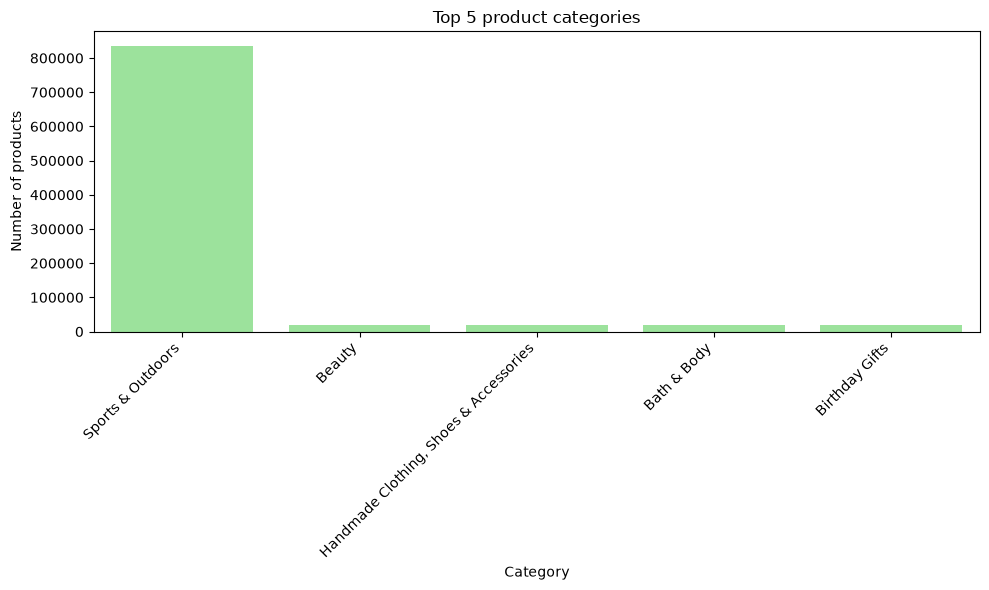

In [27]:
top = df["category"].value_counts().head(5)

plt.figure(figsize=(10, 6))
sns.barplot(x=top.index, y=top.values, color="lightgreen")
plt.title("Top 5 product categories")
plt.xlabel("Category")
plt.ylabel("Number of products")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

    - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

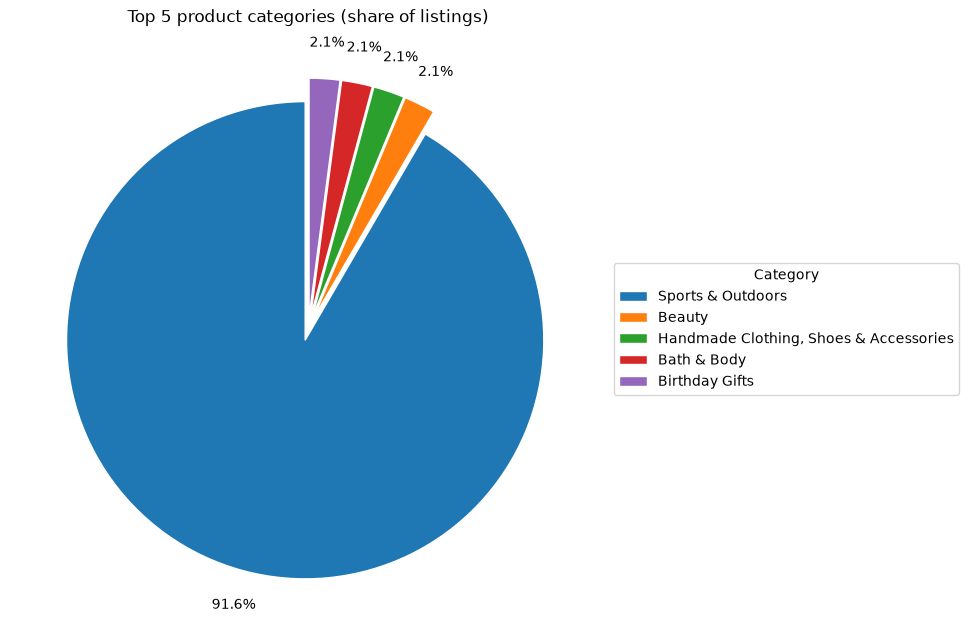

In [30]:
top = df["category"].value_counts().head(5)

explode = [0.05] * len(top)

plt.figure(figsize=(9, 7))
wedges, texts, autotexts = plt.pie(
    top.values,
    autopct="%1.1f%%",
    startangle=90,
    explode=explode,
    pctdistance=1.15,
    wedgeprops={"edgecolor": "white"},
)
plt.legend(wedges, top.index, title="Category", loc="center left", bbox_to_anchor=(1, 0.5))
plt.title("Top 5 product categories (share of listings)")
plt.tight_layout()
plt.show()

Sports & Outdoors dominates among the top 5 categories, representing 91.6% of their combined listings, while the other four are roughly equal at around 2% each

**Part 2: Delving into Product Pricing**

**Business Question:** *How are products priced on Amazon UK, and are there specific price points or ranges that are more common?*

**Measures of Centrality:**

    - Calculate the mean, median, and mode for the price of products.

In [45]:
mean_price = df["price"].mean().round(1)
median_price = df["price"].median()
mode_price = df["price"].mode()[0]

print(mean_price)
print(median_price)
print(mode_price)

89.2
19.09
9.99


In [44]:
difference_price = mean_prince - mode_price
print(difference_price.round(2))

79.21


    - What's the average price point of products listed? How does this compare with the most common price point (mode)?

*The average price point of listed products is 89.2. Compared to the mode there is a difference of around 79, meaning that there are some price outliers increasing the price mean.*

**2. Measures of Dispersion:**

    -Determine the variance, standard deviation, range, and interquartile range for product price.

In [54]:
var_price = df["price"].var()
std_price = df["price"].std()
range_price = df["price"].max() - df["price"].min()
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)
iqr_price = Q3 - Q1

print(var_price)
print(std_price.round(2))
print(range_price.round(2))
print(iqr_price)

119445.48532254901
345.61
100000.0
36.0


    - How varied are the product prices? Are there any indicators of a significant spread in prices?

*Product prices are highly variable, but mostly because of some extreme values.
The standard deviation is almost four times the mean  and the range is 100000.
The IQR is only 36, meaning that half of the products cost between 9.99 and 45.99.
Most listings are cheap and clustered together, while a small number of very expensive products inflate the spread and the average.*

**Part 3: Unpacking Product Ratings**

*Business Question: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?*



**Measures of Centrality:**

    - Calculate the mean, median, and mode for the rating of products.

In [59]:
mean_rating = df["stars"].mean().round(1)
median_rating = df["stars"].median()
mode_rating = df["stars"].mode()[0]

print(mean_rating)
print(median_rating)
print(mode_rating)

2.2
0.0
0.0


    - How do customers generally rate products? Is there a common trend?

*Most products have no customer rating, the median and mode of the ratings are 0.0.
This pulls the mean down to 2.2, so the average does not reflect how customers rate the products that do have reviews.
The common trend seems to be the lack of ratings instead of low ratings.*

**Measures of Dispersion:**

    - Determine the variance, standard deviation, and interquartile range for product rating.


In [63]:
var_rating = df["stars"].var()
std_rating = df["stars"].std()
range_rating = df["stars"].max() - df["stars"].min()
Q1 = df["stars"].quantile(0.25)
Q3 = df["stars"].quantile(0.75)
iqr_rating = Q3 - Q1

print(var_rating)
print(std_rating.round(2))
print(range_rating.round(2))
print(iqr_rating)

4.817434029796864
2.19
5.0
4.4


    - Are the ratings consistent, or is there a wide variation in customer feedback?

*The ratings are not consistent.
There is a wide variation, though most of it seems to come from the unrated products instead of customers disagreeing.
Together with the earlier result, this points to two groups: a large group of products with 0 stars (no rating) and another group with high ratings (around 4+).
The spread seems to exists because of the gap between those two groups.*

**Shape of the Distribution:**

    - Calculate the skewness and kurtosis for the rating column.

In [65]:
skewness_rating = df['stars'].skew().round(1)
kurtosis_rating = df['stars'].kurtosis().round(1)

skewness_rating, kurtosis_rating

(np.float64(0.1), np.float64(-1.9))

    - Are the ratings normally distributed, or do they lean towards higher or lower values?

*The ratings are not normally distributed and they don’t clearly lean toward higher or lower values.*

*Skewness (0.1) - This is close to 0, so the distribution is roughly symmetric, with no strong lean either way.*

*Kurtosis (-1.9): A value this negative means a very flat distribution with light tails and no central peak. It is typical of data split into two separate clusters.*

**Visualizations:**

    - Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

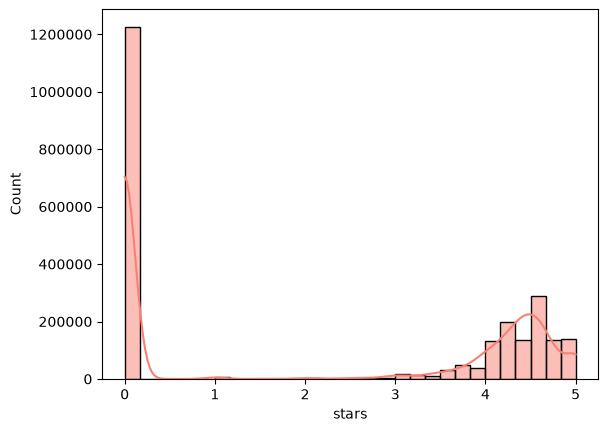

In [72]:
fig, axes = plt.subplots()
sns.histplot(df["stars"], kde=True, bins=30, color="salmon", ax=axes);
axes.ticklabel_format(style="plain", axis="y")
plt.show()

*Yes. The most common rating is 0, with more than 1.2 million products, which means they have not been rated.
Among rated products, ratings concentrate at the high end, with a peak around 4.5 stars.
The histogram confirms the earlier findings, a large number of unrated products, so for an analysis of real customer ratings, the 0-star products should be excluded.*